In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

files = os.listdir('/content/drive/MyDrive')

for f in files:
    if f.endswith('.xlsx'):
        print(f)

bus_preference_data.xlsx
A Data Driven Machine Learning Approach to Predicting Passenger Mode Preference in SriLanka (Responses).xlsx


In [ ]:
import pandas as pd

In [ ]:
original = pd.read_excel(
    '/content/drive/MyDrive/A Data Driven Machine Learning Approach to Predicting Passenger Mode Preference in SriLanka (Responses).xlsx'
)

print("Shape:", original.shape)
print("\nColumns:")
print(original.columns.tolist())

Shape: (737, 36)

Columns:
['Timestamp', '1. What is your hometown?', '2. What is your age?', '3. What is your gender?', '4. What is your occupation?', '5. What is your approximate monthly income (LKR)?', '6. Do you own any personal vehicles?', '7. How frequently do you use bus services?', '8. Which type of bus do you use most frequently?', '9. What is your most common travel route?', '10. What is the approximate distance of this trip?', '11. What is the main purpose of your bus travel?', '12. If both SLTB and private buses are available, which do you usually prefer?', '13. How important are the following factors when choosing a SLTB services ?\n(1 = Not Important, 5 = Very Important) [Service frequency]', '13. How important are the following factors when choosing a SLTB services ?\n(1 = Not Important, 5 = Very Important) [Fare / Cost]', '13. How important are the following factors when choosing a SLTB services ?\n(1 = Not Important, 5 = Very Important) [Comfort]', '13. How important a

In [ ]:
print(
    original['2. What is your age?']
    .value_counts(bins=[0, 17, 23, 29, 36, 45, 75])
    .sort_index()
)

(-0.001, 17.0]      5
(17.0, 23.0]       67
(23.0, 29.0]      210
(29.0, 36.0]      109
(36.0, 45.0]      142
(45.0, 75.0]      125
Name: count, dtype: int64


In [ ]:
import pandas as pd

df = pd.read_excel('/content/drive/MyDrive/bus_preference_data.xlsx')

print("Processed:", df.shape)

Processed: (724, 19)


In [ ]:
print("Original:", original.shape)
print("Processed:", df.shape)

print("\nOriginal target:")
print(original['12. If both SLTB and private buses are available, which do you usually prefer?'].value_counts(dropna=False))

print("\nProcessed target:")
print(df['Bus_Preference'].value_counts(dropna=False))

Original: (737, 36)
Processed: (724, 19)

Original target:
12. If both SLTB and private buses are available, which do you usually prefer?
SLTB bus        347
Private bus     290
NaN              79
SLTB බස්         12
පෞද්ගලික බස්      9
Name: count, dtype: int64

Processed target:
Bus_Preference
SLTB bus       403
Private Bus    321
Name: count, dtype: int64


In [ ]:
print("Original target values:")
print(original['12. If both SLTB and private buses are available, which do you usually prefer?'].unique())

print("\nProcessed target values:")
print(df['Bus_Preference'].unique())

Original target values:
['SLTB bus' 'Private bus' 'පෞද්ගලික බස්' 'SLTB බස්' nan]

Processed target values:
['SLTB bus' 'Private Bus']


In [ ]:
# Check completely empty rows
empty_rows = original.isna().all(axis=1).sum()

print("Completely empty rows:", empty_rows)

# Check rows with missing target
print("Missing target:", original[
    '12. If both SLTB and private buses are available, which do you usually prefer?'
].isna().sum())

Completely empty rows: 0
Missing target: 79


In [ ]:
# Check missing values in the original dataset
missing = original.isna().sum()

print("Columns with missing values:")
print(missing[missing > 0].sort_values(ascending=False))

Columns with missing values:
19. What ONE improvement would most improve your bus travel experience?                                                                              219
13. How important are the following factors when choosing a SLTB services ?\n(1 = Not Important, 5 = Very Important) [Safety]                         81
16. What is/are the PRIMARY reason/s you choose Private Buses? (can choose more than one)                                                             80
3. What is your gender?                                                                                                                               79
2. What is your age?                                                                                                                                  79
1. What is your hometown?                                                                                                                             79
4. What is your occupation?                          

In [ ]:
print("ORIGINAL:")
display(original.head(3))

print("\nPROCESSED:")
display(df.head(3))

ORIGINAL:


,Timestamp,1. What is your hometown?,2. What is your age?,3. What is your gender?,4. What is your occupation?,5. What is your approximate monthly income (LKR)?,6. Do you own any personal vehicles?,7. How frequently do you use bus services?,8. Which type of bus do you use most frequently?,9. What is your most common travel route?,...,"14. How important are the following factors when choosing a Private Bus services ?\n(1 = Not Important, 5 = Very Important) [Cleanliness]","14. How important are the following factors when choosing a Private Bus services ?\n(1 = Not Important, 5 = Very Important) [Safety]","14. How important are the following factors when choosing a Private Bus services ?\n(1 = Not Important, 5 = Very Important) [Air conditioning]","14. How important are the following factors when choosing a Private Bus services ?\n(1 = Not Important, 5 = Very Important) [Driver behaviour]","14. How important are the following factors when choosing a Private Bus services ?\n(1 = Not Important, 5 = Very Important) [Overall Reliability]",15. What is/are the PRIMARY reason/s you choose SLTB buses?\n(can choose more than one),16. What is/are the PRIMARY reason/s you choose Private Buses? (can choose more than one),17. What prevents you from using buses more often?,18. How long do you usually wait for a bus?,19. What ONE improvement would most improve your bus travel experience?
0,1,Ampara,23.0,Male,Student,No income,No,Daily (5–7 days per week),SLTB Normal,Ampara to Colombo,...,Column 2,Column 1,Column 2,Column 2,Column 2,"More frequent buses, Safer driving, Better rou...",More frequent buses,"Poor comfort, Old buses, Limited routes",5 – 10 minutes,Good
1,2,Eheliyagoda,24.0,Male,Student,"Less than 30,000",No,Frequently (3–4 days per week),Private Normal,Ratnapura - Colombo,...,4,4,Column 3,Column 3,4,"Faster travel time, More frequent buses, More ...","Faster travel time, More reliable schedule, Mo...","Overcrowding, Slow travel time",More than 20 minutes,More frequency of Intercity Buses
2,3,Batticaloa,26.0,Male,Student,No income,Motorcycle,Rarely (less than once per week),SLTB Normal,Batticaloa to Colombo,...,4,4,5,4,4,"Lower fare, Faster travel time, More frequent ...","More comfortable, Safer driving, Better bus co...","Poor comfort, Overcrowding, Unreliable schedules",10 – 20 minutes,Improve the comfortable



PROCESSED:


,Gender,Age_Group,Occupation,Monthly_Income_LKR,Bus_Usage_Frequency,Bus_Type_Used,Trip_Distance,Travel_Purpose,Bus_Preference,Wait_Time,Service_freq,Fare,Comfort,Crowding,Cleanliness,Safety,AC,Driver,Reliability
0,Male,2026-12-24 00:00:00,Student,No Income,Daily (5â€“7 days per week),SLTB Normal,More than 40 km,Education,SLTB bus,5 â€“ 10 minutes,2,2,2,2,2,3,1,2,2
1,Male,2026-12-24 00:00:00,Student,"Less than 30,000",Frequently (3â€“4 days per week),Private Normal,20 â€“ 40 km,Education,Private Bus,More than 20 minutes,5,4,4,5,4,4,4,3,4
2,Male,24 - 29,Student,No Income,Rarely (less than once per week),SLTB Normal,More than 40 km,Education,SLTB bus,10 â€“ 20 minutes,4,3,4,5,4,5,4,5,5


In [ ]:
print(df['Age_Group'].value_counts(dropna=False))


Age_Group
24 - 29                158
37 - 45                154
2026-12-24 00:00:00    138
30 - 36                137
45 - 75                137
Name: count, dtype: int64


In [ ]:
# Show original ages for the first 10 rows
print(original['2. What is your age?'].head(10).to_list())

# Show processed age groups for the first 10 rows
print(df['Age_Group'].head(10).to_list())

[23.0, 24.0, 26.0, 25.0, 25.0, 25.0, 24.0, 25.0, 26.0, 37.0]
[datetime.datetime(2026, 12, 24, 0, 0), datetime.datetime(2026, 12, 24, 0, 0), '24 - 29', '24 - 29', '24 - 29', datetime.datetime(2026, 12, 24, 0, 0), '24 - 29', '24 - 29', '37 - 45', datetime.datetime(2026, 12, 24, 0, 0)]


In [ ]:
print("Original first 724:")
print(original['2. What is your age?'].head(724).notna().sum())

print("Processed rows:")
print(len(df))

Original first 724:
658
Processed rows:
724


In [ ]:
print(df.index[:20].tolist())
print(df.index[-20:].tolist())

print("\nOriginal index:")
print(original.index[:20].tolist())

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
[704, 705, 706, 707, 708, 709, 710, 711, 712, 713, 714, 715, 716, 717, 718, 719, 720, 721, 722, 723]

Original index:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


In [ ]:
# Compare the first processed row with the first original row
print("Processed row 0:")
display(df.iloc[[0]])

print("\nOriginal row 0:")
display(original.iloc[[0]])

Processed row 0:


,Gender,Age_Group,Occupation,Monthly_Income_LKR,Bus_Usage_Frequency,Bus_Type_Used,Trip_Distance,Travel_Purpose,Bus_Preference,Wait_Time,Service_freq,Fare,Comfort,Crowding,Cleanliness,Safety,AC,Driver,Reliability
0,Male,2026-12-24 00:00:00,Student,No Income,Daily (5â€“7 days per week),SLTB Normal,More than 40 km,Education,SLTB bus,5 â€“ 10 minutes,2,2,2,2,2,3,1,2,2



Original row 0:


,Timestamp,1. What is your hometown?,2. What is your age?,3. What is your gender?,4. What is your occupation?,5. What is your approximate monthly income (LKR)?,6. Do you own any personal vehicles?,7. How frequently do you use bus services?,8. Which type of bus do you use most frequently?,9. What is your most common travel route?,...,"14. How important are the following factors when choosing a Private Bus services ?\n(1 = Not Important, 5 = Very Important) [Cleanliness]","14. How important are the following factors when choosing a Private Bus services ?\n(1 = Not Important, 5 = Very Important) [Safety]","14. How important are the following factors when choosing a Private Bus services ?\n(1 = Not Important, 5 = Very Important) [Air conditioning]","14. How important are the following factors when choosing a Private Bus services ?\n(1 = Not Important, 5 = Very Important) [Driver behaviour]","14. How important are the following factors when choosing a Private Bus services ?\n(1 = Not Important, 5 = Very Important) [Overall Reliability]",15. What is/are the PRIMARY reason/s you choose SLTB buses?\n(can choose more than one),16. What is/are the PRIMARY reason/s you choose Private Buses? (can choose more than one),17. What prevents you from using buses more often?,18. How long do you usually wait for a bus?,19. What ONE improvement would most improve your bus travel experience?
0,1,Ampara,23.0,Male,Student,No income,No,Daily (5–7 days per week),SLTB Normal,Ampara to Colombo,...,Column 2,Column 1,Column 2,Column 2,Column 2,"More frequent buses, Safer driving, Better rou...",More frequent buses,"Poor comfort, Old buses, Limited routes",5 – 10 minutes,Good


In [ ]:
# Compare key columns between processed row 0 and original row 0

print("Gender:", df.iloc[0]['Gender'], " | ", original.iloc[0]['3. What is your gender?'])
print("Occupation:", df.iloc[0]['Occupation'], " | ", original.iloc[0]['4. What is your occupation?'])
print("Income:", df.iloc[0]['Monthly_Income_LKR'], " | ", original.iloc[0]['5. What is your approximate monthly income (LKR)?'])
print("Bus type:", df.iloc[0]['Bus_Type_Used'], " | ", original.iloc[0]['8. Which type of bus do you use most frequently?'])
print("Purpose:", df.iloc[0]['Travel_Purpose'], " | ", original.iloc[0]['11. What is the main purpose of your bus travel?'])
print("Preference:", df.iloc[0]['Bus_Preference'], " | ", original.iloc[0]['12. If both SLTB and private buses are available, which do you usually prefer?'])

Gender: Male  |  Male
Occupation: Student  |  Student
Income: No Income  |  No income
Bus type: SLTB Normal  |  SLTB Normal
Purpose: Education  |  Education
Preference: SLTB bus  |  SLTB bus


In [ ]:
# Check whether processed rows match the original rows
checks = []

for i in range(len(df)):
    match = (
        df.iloc[i]['Gender'] == original.iloc[i]['3. What is your gender?']
        and df.iloc[i]['Occupation'] == original.iloc[i]['4. What is your occupation?']
        and df.iloc[i]['Bus_Type_Used'] == original.iloc[i]['8. Which type of bus do you use most frequently?']
        and df.iloc[i]['Travel_Purpose'] == original.iloc[i]['11. What is the main purpose of your bus travel?']
    )
    checks.append(match)

print("Matching rows:", sum(checks))
print("Non-matching rows:", len(checks) - sum(checks))

Matching rows: 13
Non-matching rows: 711


In [ ]:
checks = []

for i in range(len(df)):
    match = (
        df.iloc[i]['Gender'] == original.iloc[i]['3. What is your gender?']
        and df.iloc[i]['Occupation'] == original.iloc[i]['4. What is your occupation?']
        and df.iloc[i]['Bus_Type_Used'] == original.iloc[i]['8. Which type of bus do you use most frequently?']
        and df.iloc[i]['Travel_Purpose'] == original.iloc[i]['11. What is the main purpose of your bus travel?']
    )
    checks.append(match)

print("Matching rows:", sum(checks))
print("Non-matching rows:", len(checks) - sum(checks))

Matching rows: 13
Non-matching rows: 711


In [ ]:
# Create a simple matching key from fields that should identify the same response

original['match_key'] = (
    original['3. What is your gender?'].astype(str) + '|' +
    original['4. What is your occupation?'].astype(str) + '|' +
    original['5. What is your approximate monthly income (LKR)?'].astype(str) + '|' +
    original['8. Which type of bus do you use most frequently?'].astype(str) + '|' +
    original['11. What is the main purpose of your bus travel?'].astype(str)
)

df['match_key'] = (
    df['Gender'].astype(str) + '|' +
    df['Occupation'].astype(str) + '|' +
    df['Monthly_Income_LKR'].astype(str) + '|' +
    df['Bus_Type_Used'].astype(str) + '|' +
    df['Travel_Purpose'].astype(str)
)

# Count how many processed rows have a matching key in the original
original_keys = set(original['match_key'])

matches = df['match_key'].isin(original_keys)

print("Processed rows with a possible original match:", matches.sum())
print("Processed rows without a match:", (~matches).sum())

Processed rows with a possible original match: 38
Processed rows without a match: 686


In [ ]:
# Normalize target values in the original dataset

target_map = {
    'SLTB bus': 'SLTB bus',
    'SLTB බස්': 'SLTB bus',
    'Private bus': 'Private Bus',
    'පෞද්ගලික බස්': 'Private Bus'
}

original_target = original[
    '12. If both SLTB and private buses are available, which do you usually prefer?'
].map(target_map)

print("Original normalized target:")
print(original_target.value_counts(dropna=False))

print("\nProcessed target:")
print(df['Bus_Preference'].value_counts(dropna=False))

Original normalized target:
12. If both SLTB and private buses are available, which do you usually prefer?
SLTB bus       359
Private Bus    299
NaN             79
Name: count, dtype: int64

Processed target:
Bus_Preference
SLTB bus       403
Private Bus    321
Name: count, dtype: int64


In [ ]:
print("Processed duplicate rows:", df.duplicated().sum())

print("\nAge group counts:")
print(df['Age_Group'].value_counts())

print("\nTarget by age group:")
print(pd.crosstab(df['Age_Group'], df['Bus_Preference']))

Processed duplicate rows: 2

Age group counts:
Age_Group
24 - 29                158
37 - 45                154
2026-12-24 00:00:00    138
30 - 36                137
45 - 75                137
Name: count, dtype: int64

Target by age group:
Bus_Preference       Private Bus  SLTB bus
Age_Group                                 
2026-12-24 00:00:00           57        81
24 - 29                       73        85
30 - 36                       67        70
37 - 45                       61        93
45 - 75                       63        74


In [ ]:
print(df.loc[df['Age_Group'].astype(str).str.contains('2026-12-24'),
             ['Age_Group', 'Gender', 'Occupation', 'Monthly_Income_LKR',
              'Bus_Type_Used', 'Trip_Distance', 'Travel_Purpose',
              'Bus_Preference']].head(20))

              Age_Group  Gender               Occupation Monthly_Income_LKR  \
0   2026-12-24 00:00:00    Male                  Student          No Income   
1   2026-12-24 00:00:00    Male                  Student   Less than 30,000   
5   2026-12-24 00:00:00    Male                  Student          No Income   
9   2026-12-24 00:00:00    Male                  Student          No Income   
10  2026-12-24 00:00:00    Male            Self-Employed  More than 250,000   
14  2026-12-24 00:00:00    Male                  Student          No Income   
15  2026-12-24 00:00:00    Male                  Student          No Income   
16  2026-12-24 00:00:00  Female                  Student          No Income   
17  2026-12-24 00:00:00  Female                  Student          No Income   
18  2026-12-24 00:00:00    Male                  Student          No Income   
19  2026-12-24 00:00:00    Male  Private Sector Employee      50,000-75,000   
21  2026-12-24 00:00:00    Male                  Stu

In [ ]:
print("Total columns:", len(df.columns))

print("\nColumns:")
for i, col in enumerate(df.columns, 1):
    print(i, col)

print("\nTarget:", 'Bus_Preference')
print("Input features:", len(df.columns) - 1)

Total columns: 20

Columns:
1 Gender
2 Age_Group
3 Occupation
4 Monthly_Income_LKR
5 Bus_Usage_Frequency
6 Bus_Type_Used
7 Trip_Distance
8 Travel_Purpose
9 Bus_Preference
10 Wait_Time
11 Service_freq
12 Fare
13 Comfort
14 Crowding
15 Cleanliness
16 Safety
17 AC
18 Driver
19 Reliability
20 match_key

Target: Bus_Preference
Input features: 19


In [ ]:
df = df.drop(columns=['match_key'])

print("Columns:", len(df.columns))
print(df.columns.tolist())

Columns: 19
['Gender', 'Age_Group', 'Occupation', 'Monthly_Income_LKR', 'Bus_Usage_Frequency', 'Bus_Type_Used', 'Trip_Distance', 'Travel_Purpose', 'Bus_Preference', 'Wait_Time', 'Service_freq', 'Fare', 'Comfort', 'Crowding', 'Cleanliness', 'Safety', 'AC', 'Driver', 'Reliability']


In [ ]:
print("Dataset shape:", df.shape)

print("\nTarget distribution:")
print(df['Bus_Preference'].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (724, 19)

Target distribution:
Bus_Preference
SLTB bus       403
Private Bus    321
Name: count, dtype: int64

Missing values:
Gender                  0
Age_Group               0
Occupation              0
Monthly_Income_LKR      0
Bus_Usage_Frequency     0
Bus_Type_Used           0
Trip_Distance           0
Travel_Purpose          0
Bus_Preference          0
Wait_Time              21
Service_freq            0
Fare                    0
Comfort                 0
Crowding                0
Cleanliness             0
Safety                  0
AC                      0
Driver                  0
Reliability             0
dtype: int64


In [ ]:
df['Wait_Time'] = df['Wait_Time'].fillna(df['Wait_Time'].mode()[0])

print("Missing values after filling:")
print(df.isnull().sum().sum())

print("\nWait_Time values:")
print(df['Wait_Time'].value_counts())

Missing values after filling:
0

Wait_Time values:
Wait_Time
5 â€“ 10 minutes        277
10 â€“ 20 minutes       223
More than 20 minutes    155
Less than 5 minutes      69
Name: count, dtype: int64


In [ ]:
print(df.dtypes)


Gender                 object
Age_Group              object
Occupation             object
Monthly_Income_LKR     object
Bus_Usage_Frequency    object
Bus_Type_Used          object
Trip_Distance          object
Travel_Purpose         object
Bus_Preference         object
Wait_Time              object
Service_freq            int64
Fare                    int64
Comfort                 int64
Crowding                int64
Cleanliness             int64
Safety                  int64
AC                      int64
Driver                  int64
Reliability             int64
dtype: object


In [ ]:
df['Age_Group'] = df['Age_Group'].astype(str)

print(df['Age_Group'].value_counts())
print("\nAge_Group data type:", df['Age_Group'].dtype)

Age_Group
24 - 29                158
37 - 45                154
2026-12-24 00:00:00    138
30 - 36                137
45 - 75                137
Name: count, dtype: int64

Age_Group data type: object


In [ ]:
from sklearn.preprocessing import LabelEncoder

df_encoded = df.copy()

categorical_cols = [
    'Gender',
    'Age_Group',
    'Occupation',
    'Monthly_Income_LKR',
    'Bus_Usage_Frequency',
    'Bus_Type_Used',
    'Trip_Distance',
    'Travel_Purpose',
    'Wait_Time'
]

label_encoders = {}

for col in categorical_cols:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_encoded[col])
    label_encoders[col] = le

# Encode target
target_encoder = LabelEncoder()
df_encoded['Bus_Preference'] = target_encoder.fit_transform(
    df_encoded['Bus_Preference']
)

print(df_encoded.head())
print("\nShape:", df_encoded.shape)

   Gender  Age_Group  Occupation  Monthly_Income_LKR  Bus_Usage_Frequency  \
0       1          0           5                   7                    0   
1       1          0           5                   5                    1   
2       1          1           5                   7                    3   
3       1          1           5                   5                    3   
4       1          1           2                   2                    0   

   Bus_Type_Used  Trip_Distance  Travel_Purpose  Bus_Preference  Wait_Time  \
0              4              4               1               1          1   
1              1              1               1               0          3   
2              4              4               1               1          0   
3              4              4               1               1          1   
4              4              4               6               1          3   

   Service_freq  Fare  Comfort  Crowding  Cleanliness  Safety  AC  D

In [ ]:
X = df_encoded.drop(columns=['Bus_Preference'])
y = df_encoded['Bus_Preference']

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget values:")
print(y.value_counts())

X shape: (724, 18)
y shape: (724,)

Target values:
Bus_Preference
1    403
0    321
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining target:")
print(y_train.value_counts())

print("\nTest target:")
print(y_test.value_counts())

Training set: (506, 18)
Test set: (218, 18)

Training target:
Bus_Preference
1    282
0    224
Name: count, dtype: int64

Test target:
Bus_Preference
1    121
0     97
Name: count, dtype: int64


In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

xgb_model = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)

xgb_model.fit(X_train, y_train)

y_pred = xgb_model.predict(X_test)
y_prob = xgb_model.predict_proba(X_test)[:, 1]

print("Baseline XGBoost Results")
print("------------------------")
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))
print("AUC-ROC  :", roc_auc_score(y_test, y_prob))

Baseline XGBoost Results
------------------------
Accuracy : 0.8577981651376146
Precision: 0.8515625
Recall   : 0.9008264462809917
F1 Score : 0.8755020080321285
AUC-ROC  : 0.922211808809747


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)
dt_prob = dt_model.predict_proba(X_test)[:, 1]

print("Decision Tree Results")
print("---------------------")
print("Accuracy :", accuracy_score(y_test, dt_pred))
print("Precision:", precision_score(y_test, dt_pred))
print("Recall   :", recall_score(y_test, dt_pred))
print("F1 Score :", f1_score(y_test, dt_pred))
print("AUC-ROC  :", roc_auc_score(y_test, dt_prob))


Decision Tree Results
---------------------
Accuracy : 0.7844036697247706
Precision: 0.8083333333333333
Recall   : 0.8016528925619835
F1 Score : 0.8049792531120332
AUC-ROC  : 0.7822697452500639


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest Results")
print("---------------------")
print("Accuracy :", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall   :", recall_score(y_test, rf_pred))
print("F1 Score :", f1_score(y_test, rf_pred))
print("AUC-ROC  :", roc_auc_score(y_test, rf_prob))

Random Forest Results
---------------------
Accuracy : 0.8394495412844036
Precision: 0.8412698412698413
Recall   : 0.8760330578512396
F1 Score : 0.8582995951417004
AUC-ROC  : 0.9237028201414331


In [ ]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)
lr_prob = lr_model.predict_proba(X_test)[:, 1]

print("Logistic Regression Results")
print("---------------------------")
print("Accuracy :", accuracy_score(y_test, lr_pred))
print("Precision:", precision_score(y_test, lr_pred))
print("Recall   :", recall_score(y_test, lr_pred))
print("F1 Score :", f1_score(y_test, lr_pred))
print("AUC-ROC  :", roc_auc_score(y_test, lr_prob))

Logistic Regression Results
---------------------------
Accuracy : 0.8302752293577982
Precision: 0.828125
Recall   : 0.8760330578512396
F1 Score : 0.8514056224899599
AUC-ROC  : 0.9185481809661753


In [ ]:
!pip install deap -q

from deap import base, creator, tools, algorithms
import random
import numpy as np

print("DEAP is ready!")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 93.1/93.1 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 879.5/879.5 kB 19.6 MB/s eta 0:00:00
DEAP is ready!


In [ ]:
num_features = X_train.shape[1]

print("Number of input features:", num_features)

# Example chromosome
chromosome = [random.randint(0, 1) for _ in range(num_features)]

print("Example chromosome:")
print(chromosome)

print("Selected features:", sum(chromosome))

Number of input features: 18
Example chromosome:
[0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1]
Selected features: 7


In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from xgboost import XGBClassifier

def evaluate_chromosome(individual):
    selected_features = [
        i for i, bit in enumerate(individual) if bit == 1
    ]

    # Prevent a chromosome with no selected features
    if len(selected_features) == 0:
        return (0.0,)

    X_selected = X_train.iloc[:, selected_features]

    model = XGBClassifier(
        random_state=42,
        eval_metric='logloss'
    )

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    scores = cross_val_score(
        model,
        X_selected,
        y_train,
        cv=cv,
        scoring='f1'
    )

    return (scores.mean(),)

print("Fitness function created successfully!")

Fitness function created successfully!


In [ ]:
# Clear previous DEAP classes if they already exist
if hasattr(creator, "FitnessMax"):
    del creator.FitnessMax

if hasattr(creator, "Individual"):
    del creator.Individual

# Higher F1-score is better
creator.create("FitnessMax", base.Fitness, weights=(1.0,))

# Individual = chromosome
creator.create(
    "Individual",
    list,
    fitness=creator.FitnessMax
)

toolbox = base.Toolbox()

# Generate 0/1 genes
toolbox.register(
    "attr_bool",
    random.randint,
    0,
    1
)

# Create an individual with 18 genes
toolbox.register(
    "individual",
    tools.initRepeat,
    creator.Individual,
    toolbox.attr_bool,
    n=num_features
)

# Create population
toolbox.register(
    "population",
    tools.initRepeat,
    list,
    toolbox.individual
)

# Genetic Algorithm operations
toolbox.register(
    "evaluate",
    evaluate_chromosome
)

toolbox.register(
    "mate",
    tools.cxOnePoint
)

toolbox.register(
    "mutate",
    tools.mutFlipBit,
    indpb=0.05
)

toolbox.register(
    "select",
    tools.selTournament,
    tournsize=3
)

print("GA toolbox created successfully!")

GA toolbox created successfully!


In [ ]:
# Create initial population
population = toolbox.population(n=10)

print("Initial population size:", len(population))

# Run GA
for generation in range(5):

    # Evaluate individuals without a fitness value
    invalid_individuals = [
        ind for ind in population
        if not ind.fitness.valid
    ]

    fitnesses = map(toolbox.evaluate, invalid_individuals)

    for ind, fitness in zip(invalid_individuals, fitnesses):
        ind.fitness.values = fitness

    # Select the next generation
    offspring = toolbox.select(population, len(population))
    offspring = list(map(toolbox.clone, offspring))

    # Crossover
    for child1, child2 in zip(offspring[::2], offspring[1::2]):
        if random.random() < 0.7:
            toolbox.mate(child1, child2)
            del child1.fitness.values
            del child2.fitness.values

    # Mutation
    for mutant in offspring:
        if random.random() < 0.2:
            toolbox.mutate(mutant)
            del mutant.fitness.values

    population[:] = offspring

    print(f"Generation {generation + 1}/5 completed")

# Evaluate final population
for ind in population:
    if not ind.fitness.valid:
        ind.fitness.values = toolbox.evaluate(ind)

best_individual = tools.selBest(population, 1)[0]

print("\nBest chromosome:")
print(best_individual)

print("\nBest CV F1-score:")
print(best_individual.fitness.values[0])

print("\nNumber of selected features:")
print(sum(best_individual))

Initial population size: 10
Generation 1/5 completed
Generation 2/5 completed
Generation 3/5 completed
Generation 4/5 completed
Generation 5/5 completed

Best chromosome:
[0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0]

Best CV F1-score:
0.8845058981392718

Number of selected features:
9


In [ ]:
selected_features = [
    feature for feature, bit in zip(X.columns, best_individual)
    if bit == 1
]

print("Selected features:")
for i, feature in enumerate(selected_features, 1):
    print(i, feature)

print("\nTotal selected:", len(selected_features))

Selected features:
1 Monthly_Income_LKR
2 Bus_Type_Used
3 Trip_Distance
4 Travel_Purpose
5 Wait_Time
6 Service_freq
7 Comfort
8 Crowding
9 AC

Total selected: 9


In [ ]:
X_train_ga = X_train[selected_features]
X_test_ga = X_test[selected_features]

print("GA-selected training shape:", X_train_ga.shape)
print("GA-selected test shape:", X_test_ga.shape)

print("\nSelected features:")
print(selected_features)

GA-selected training shape: (506, 9)
GA-selected test shape: (218, 9)

Selected features:
['Monthly_Income_LKR', 'Bus_Type_Used', 'Trip_Distance', 'Travel_Purpose', 'Wait_Time', 'Service_freq', 'Comfort', 'Crowding', 'AC']


In [ ]:
print("Best chromosome:")
print(best_individual)

print("\nChromosome length:")
print(len(best_individual))

print("\nSelected count:")
print(sum(best_individual))

Best chromosome:
[0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0]

Chromosome length:
18

Selected count:
9


In [ ]:
selected_features = [
    feature for feature, bit in zip(X.columns, best_individual)
    if bit == 1
]

print("Current GA-selected features:")
for i, feature in enumerate(selected_features, 1):
    print(i, feature)

print("\nTotal selected:", len(selected_features))

print("\nBest CV F1:", best_individual.fitness.values[0])

Current GA-selected features:
1 Monthly_Income_LKR
2 Bus_Type_Used
3 Trip_Distance
4 Travel_Purpose
5 Wait_Time
6 Service_freq
7 Comfort
8 Crowding
9 AC

Total selected: 9

Best CV F1: 0.8845058981392718


In [ ]:
# Get the features selected by the best GA chromosome
selected_features = [
    feature for feature, bit in zip(X.columns, best_individual)
    if bit == 1
]

# Create GA-selected datasets
X_train_ga = X_train[selected_features]
X_test_ga = X_test[selected_features]

print("GA-selected training shape:", X_train_ga.shape)
print("GA-selected test shape:", X_test_ga.shape)

print("\nSelected features:")
for i, feature in enumerate(selected_features, 1):
    print(i, feature)

GA-selected training shape: (506, 9)
GA-selected test shape: (218, 9)

Selected features:
1 Monthly_Income_LKR
2 Bus_Type_Used
3 Trip_Distance
4 Travel_Purpose
5 Wait_Time
6 Service_freq
7 Comfort
8 Crowding
9 AC


In [ ]:
from xgboost import XGBClassifier

# Create GA-selected XGBoost model
ga_xgb_model = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)

# Train the model
ga_xgb_model.fit(X_train_ga, y_train)

print("GA-XGBoost model trained successfully!")

GA-XGBoost model trained successfully!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Predictions
y_pred_ga = ga_xgb_model.predict(X_test_ga)

# Probabilities for AUC
y_prob_ga = ga_xgb_model.predict_proba(X_test_ga)[:, 1]

# Calculate metrics
accuracy_ga = accuracy_score(y_test, y_pred_ga)
precision_ga = precision_score(y_test, y_pred_ga)
recall_ga = recall_score(y_test, y_pred_ga)
f1_ga = f1_score(y_test, y_pred_ga)
auc_ga = roc_auc_score(y_test, y_prob_ga)

print("GA-XGBoost Test Results")
print("-----------------------")
print(f"Accuracy : {accuracy_ga:.4f}")
print(f"Precision: {precision_ga:.4f}")
print(f"Recall   : {recall_ga:.4f}")
print(f"F1-Score : {f1_ga:.4f}")
print(f"AUC-ROC  : {auc_ga:.4f}")

GA-XGBoost Test Results
-----------------------
Accuracy : 0.8028
Precision: 0.8250
Recall   : 0.8182
F1-Score : 0.8216
AUC-ROC  : 0.8875


In [ ]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest",
        "Logistic Regression",
        "XGBoost",
        "GA-XGBoost"
    ],
    "Accuracy": [
        0.7844,
        0.8394,
        0.8303,
        0.8578,
        accuracy_ga
    ],
    "Precision": [
        0.8083,
        0.8413,
        0.8281,
        0.8516,
        precision_ga
    ],
    "Recall": [
        0.8017,
        0.8760,
        0.8760,
        0.9008,
        recall_ga
    ],
    "F1-Score": [
        0.8050,
        0.8583,
        0.8514,
        0.8755,
        f1_ga
    ],
    "AUC-ROC": [
        0.7823,
        0.9237,
        0.9185,
        0.9222,
        auc_ga
    ]
})

# Convert to percentages
comparison_percent = comparison.copy()

for col in ["Accuracy", "Precision", "Recall", "F1-Score", "AUC-ROC"]:
    comparison_percent[col] = (
        comparison_percent[col] * 100
    ).round(2)

comparison_percent

,Model,Accuracy,Precision,Recall,F1-Score,AUC-ROC
0,Decision Tree,78.44,80.83,80.17,80.50,78.23
1,Random Forest,83.94,84.13,87.60,85.83,92.37
2,Logistic Regression,83.03,82.81,87.60,85.14,91.85
3,XGBoost,85.78,85.16,90.08,87.55,92.22
4,GA-XGBoost,80.28,82.50,81.82,82.16,88.75


Confusion Matrix:
[[76 21]
 [22 99]]


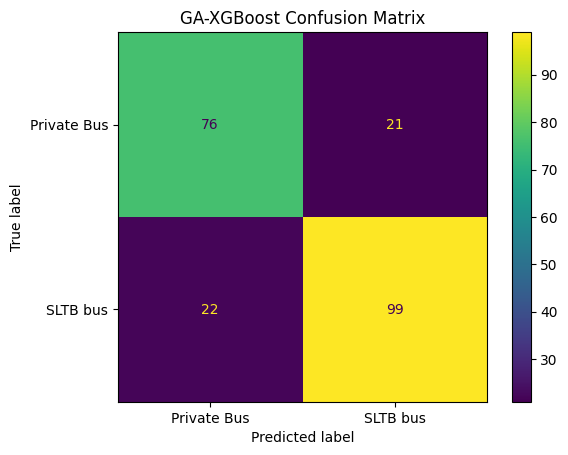

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_ga)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=target_encoder.classes_
)

disp.plot()
plt.title("GA-XGBoost Confusion Matrix")
plt.show()

Bus_Type_Used         0.310128
Service_freq          0.174159
AC                    0.129472
Comfort               0.121738
Crowding              0.061977
Travel_Purpose        0.055135
Monthly_Income_LKR    0.049856
Trip_Distance         0.049811
Wait_Time             0.047724
dtype: float32


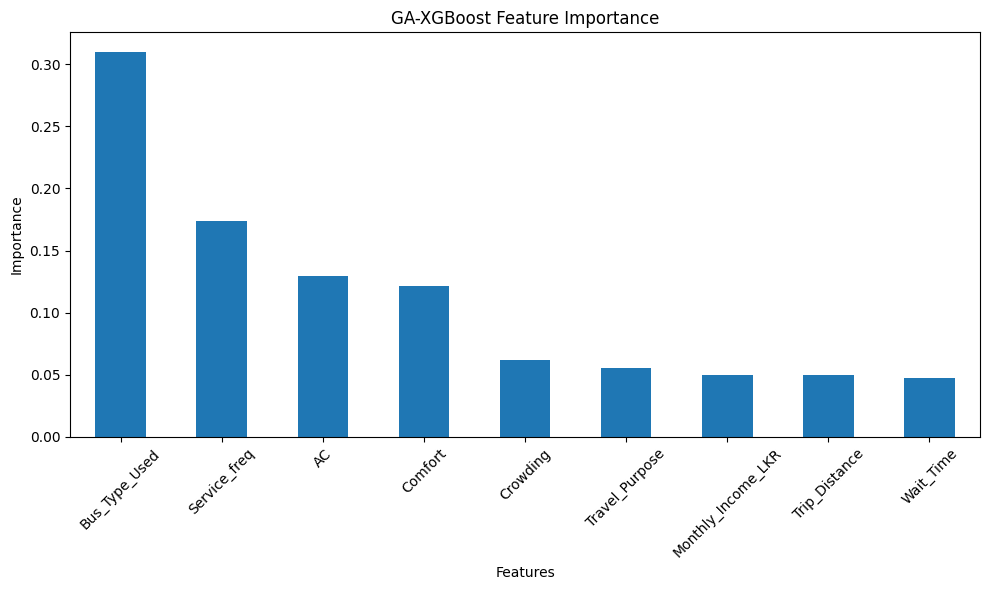

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.Series(
    ga_xgb_model.feature_importances_,
    index=X_train_ga.columns
).sort_values(ascending=False)

print(feature_importance)

feature_importance.plot(kind='bar', figsize=(10, 6))
plt.title("GA-XGBoost Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred_ga,
    target_names=target_encoder.classes_
))

              precision    recall  f1-score   support

 Private Bus       0.78      0.78      0.78        97
    SLTB bus       0.82      0.82      0.82       121

    accuracy                           0.80       218
   macro avg       0.80      0.80      0.80       218
weighted avg       0.80      0.80      0.80       218



In [ ]:
# Find incorrectly classified test samples

failure_df = X_test_ga.copy()

failure_df["Actual"] = y_test.values
failure_df["Predicted"] = y_pred_ga

failure_df["Correct"] = (
    failure_df["Actual"] == failure_df["Predicted"]
)

failures = failure_df[failure_df["Correct"] == False].copy()

print("Total test samples:", len(failure_df))
print("Incorrect predictions:", len(failures))

print("\nFailure cases:")
display(failures)

Total test samples: 218
Incorrect predictions: 43

Failure cases:


,Monthly_Income_LKR,Bus_Type_Used,Trip_Distance,Travel_Purpose,Wait_Time,Service_freq,Comfort,Crowding,AC,Actual,Predicted,Correct
84,1,2,4,0,3,5,3,4,5,1,0,False
475,3,1,0,6,1,4,3,4,4,0,1,False
183,5,4,1,3,1,4,4,4,4,1,0,False
536,5,1,1,1,3,3,3,5,3,1,0,False
458,2,1,4,0,3,5,4,5,3,1,0,False
703,4,3,0,3,1,5,4,2,3,1,0,False
630,4,4,4,4,2,4,4,4,5,0,1,False
642,4,4,0,2,0,3,5,5,4,0,1,False
230,1,1,1,6,0,1,3,1,2,1,0,False
329,4,1,4,6,3,5,3,4,4,1,0,False


In [ ]:
# Analyze the two types of classification errors

private_to_sltb = failures[
    (failures["Actual"] == 0) &
    (failures["Predicted"] == 1)
]

sltb_to_private = failures[
    (failures["Actual"] == 1) &
    (failures["Predicted"] == 0)
]

print("Private Bus → SLTB:", len(private_to_sltb))
print("SLTB → Private Bus:", len(sltb_to_private))

Private Bus → SLTB: 21
SLTB → Private Bus: 22


In [ ]:
decoded_failures = failures.copy()

# Decode only columns that are present in failures
for col, le in label_encoders.items():
    if col in decoded_failures.columns:
        decoded_failures[col] = le.inverse_transform(
            decoded_failures[col].astype(int)
        )

# Decode Actual and Predicted
decoded_failures["Actual"] = target_encoder.inverse_transform(
    decoded_failures["Actual"].astype(int)
)

decoded_failures["Predicted"] = target_encoder.inverse_transform(
    decoded_failures["Predicted"].astype(int)
)

display(decoded_failures)

,Monthly_Income_LKR,Bus_Type_Used,Trip_Distance,Travel_Purpose,Wait_Time,Service_freq,Comfort,Crowding,AC,Actual,Predicted,Correct
84,"150,000-250,000",Private Semi-Luxury,More than 40 km,Business,More than 20 minutes,5,3,4,5,SLTB bus,Private Bus,False
475,"50,000-100,000",Private Normal,10 â€“ 20 km,Work,5 â€“ 10 minutes,4,3,4,4,Private Bus,SLTB bus,False
183,"Less than 30,000",SLTB Normal,20 â€“ 40 km,Other,5 â€“ 10 minutes,4,4,4,4,SLTB bus,Private Bus,False
536,"Less than 30,000",Private Normal,20 â€“ 40 km,Education,More than 20 minutes,3,3,5,3,SLTB bus,Private Bus,False
458,"30,000-50,000",Private Normal,More than 40 km,Business,More than 20 minutes,5,4,5,3,SLTB bus,Private Bus,False
703,"50,000-75,000",Private Super XL / Express,10 â€“ 20 km,Other,5 â€“ 10 minutes,5,4,2,3,SLTB bus,Private Bus,False
630,"50,000-75,000",SLTB Normal,More than 40 km,Shopping,Less than 5 minutes,4,4,4,5,Private Bus,SLTB bus,False
642,"50,000-75,000",SLTB Normal,10 â€“ 20 km,Healthcare,10 â€“ 20 minutes,3,5,5,4,Private Bus,SLTB bus,False
230,"150,000-250,000",Private Normal,20 â€“ 40 km,Work,10 â€“ 20 minutes,1,3,1,2,SLTB bus,Private Bus,False
329,"50,000-75,000",Private Normal,More than 40 km,Work,More than 20 minutes,5,3,4,4,SLTB bus,Private Bus,False


In [ ]:
# Count failure patterns for categorical features

failure_features = [
    'Gender',
    'Age_Group',
    'Bus_Usage_Frequency',
    'Bus_Type_Used',
    'Trip_Distance',
    'Wait_Time'
]

for col in failure_features:
    print("\n==============================")
    print(col)
    print("==============================")
    print(decoded_failures[col].value_counts())


Gender


KeyError: 'Gender'

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    'accuracy': 'accuracy',
    'f1': 'f1',
    'auc': 'roc_auc'
}

print("5-Fold Cross-Validation setup completed.")

5-Fold Cross-Validation setup completed.


In [ ]:
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        random_state=42,
        eval_metric='logloss'
    )
}

cv_results = {}

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    cv_results[name] = {
        "Accuracy Mean": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "F1 Mean": scores["test_f1"].mean(),
        "F1 Std": scores["test_f1"].std(),
        "AUC Mean": scores["test_auc"].mean(),
        "AUC Std": scores["test_auc"].std()
    }

print("Baseline cross-validation completed.")

Baseline cross-validation completed.


In [ ]:
import pandas as pd

cv_table = pd.DataFrame(cv_results).T

display(cv_table)

,Accuracy Mean,Accuracy Std,F1 Mean,F1 Std,AUC Mean,AUC Std
Decision Tree,0.770782,0.024239,0.787798,0.031157,0.770835,0.020044
Logistic Regression,0.822209,0.029475,0.841308,0.027805,0.898248,0.020219
Random Forest,0.865618,0.010005,0.880798,0.012075,0.935176,0.007803
XGBoost,0.843836,0.025555,0.857775,0.025280,0.917626,0.007671


In [ ]:
# 5-Fold Cross-Validation for GA-XGBoost

ga_cv_scores = cross_validate(
    ga_xgb_model,
    X_train_ga,
    y_train,
    cv=cv,
    scoring=scoring
)

ga_cv_results = {
    "Accuracy Mean": ga_cv_scores["test_accuracy"].mean(),
    "Accuracy Std": ga_cv_scores["test_accuracy"].std(),
    "F1 Mean": ga_cv_scores["test_f1"].mean(),
    "F1 Std": ga_cv_scores["test_f1"].std(),
    "AUC Mean": ga_cv_scores["test_auc"].mean(),
    "AUC Std": ga_cv_scores["test_auc"].std()
}

print("GA-XGBoost cross-validation completed.")
print(ga_cv_results)

GA-XGBoost cross-validation completed.
{'Accuracy Mean': np.float64(0.8696175499902932), 'Accuracy Std': np.float64(0.02867571968756597), 'F1 Mean': np.float64(0.8845058981392718), 'F1 Std': np.float64(0.027847020847732856), 'AUC Mean': np.float64(0.9146131743500165), 'AUC Std': np.float64(0.01611853322126723)}


In [ ]:
# Combine all 5 model results

final_cv_results = cv_results.copy()
final_cv_results["GA-XGBoost"] = ga_cv_results

final_cv_table = pd.DataFrame(final_cv_results).T

display(final_cv_table)

,Accuracy Mean,Accuracy Std,F1 Mean,F1 Std,AUC Mean,AUC Std
Decision Tree,0.770782,0.024239,0.787798,0.031157,0.770835,0.020044
Logistic Regression,0.822209,0.029475,0.841308,0.027805,0.898248,0.020219
Random Forest,0.865618,0.010005,0.880798,0.012075,0.935176,0.007803
XGBoost,0.843836,0.025555,0.857775,0.025280,0.917626,0.007671
GA-XGBoost,0.869618,0.028676,0.884506,0.027847,0.914613,0.016119


In [ ]:
# Ablation Study: All Features vs GA-Selected Features

ablation_results = pd.DataFrame({
    "Model": [
        "XGBoost - All 18 Features",
        "GA-XGBoost - 12 Selected Features"
    ],
    "Accuracy Mean": [
        cv_results["XGBoost"]["Accuracy Mean"],
        ga_cv_results["Accuracy Mean"]
    ],
    "Accuracy Std": [
        cv_results["XGBoost"]["Accuracy Std"],
        ga_cv_results["Accuracy Std"]
    ],
    "F1 Mean": [
        cv_results["XGBoost"]["F1 Mean"],
        ga_cv_results["F1 Mean"]
    ],
    "F1 Std": [
        cv_results["XGBoost"]["F1 Std"],
        ga_cv_results["F1 Std"]
    ],
    "AUC Mean": [
        cv_results["XGBoost"]["AUC Mean"],
        ga_cv_results["AUC Mean"]
    ],
    "AUC Std": [
        cv_results["XGBoost"]["AUC Std"],
        ga_cv_results["AUC Std"]
    ]
})

display(ablation_results)

,Model,Accuracy Mean,Accuracy Std,F1 Mean,F1 Std,AUC Mean,AUC Std
0,XGBoost - All 18 Features,0.843836,0.025555,0.857775,0.025280,0.917626,0.007671
1,GA-XGBoost - 12 Selected Features,0.869618,0.028676,0.884506,0.027847,0.914613,0.016119


In [ ]:
from statsmodels.stats.contingency_tables import mcnemar
import numpy as np

# Predictions from the two models on the same test set

xgb_model = models["XGBoost"]

xgb_predictions = xgb_model.fit(
    X_train,
    y_train
).predict(X_test)

ga_predictions = ga_xgb_model.predict(X_test_ga)

# Check whether each prediction is correct
xgb_correct = xgb_predictions == y_test.to_numpy()
ga_correct = ga_predictions == y_test.to_numpy()

# McNemar contingency table
table = np.zeros((2, 2), dtype=int)

for xgb_c, ga_c in zip(xgb_correct, ga_correct):
    table[int(xgb_c), int(ga_c)] += 1

print("McNemar Contingency Table:")
print(table)

# McNemar's test
result = mcnemar(table, exact=False, correction=True)

print("\nMcNemar Test Results")
print("Statistic:", result.statistic)
print("p-value:", result.pvalue)

McNemar Contingency Table:
[[ 23   8]
 [ 20 167]]

McNemar Test Results
Statistic: 4.321428571428571
p-value: 0.03763531378731436


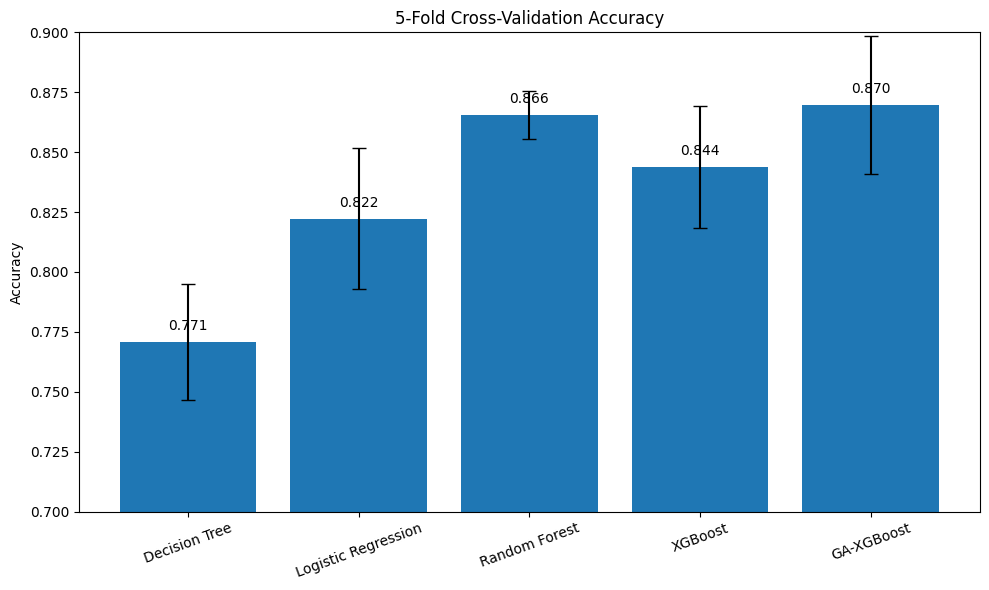

In [ ]:
import matplotlib.pyplot as plt

models_names = final_cv_table.index

accuracy_means = final_cv_table["Accuracy Mean"]
accuracy_stds = final_cv_table["Accuracy Std"]

plt.figure(figsize=(10, 6))

plt.bar(
    models_names,
    accuracy_means,
    yerr=accuracy_stds,
    capsize=5
)

plt.ylabel("Accuracy")
plt.title("5-Fold Cross-Validation Accuracy")
plt.ylim(0.7, 0.9)

for i, value in enumerate(accuracy_means):
    plt.text(
        i,
        value + 0.005,
        f"{value:.3f}",
        ha="center"
    )

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

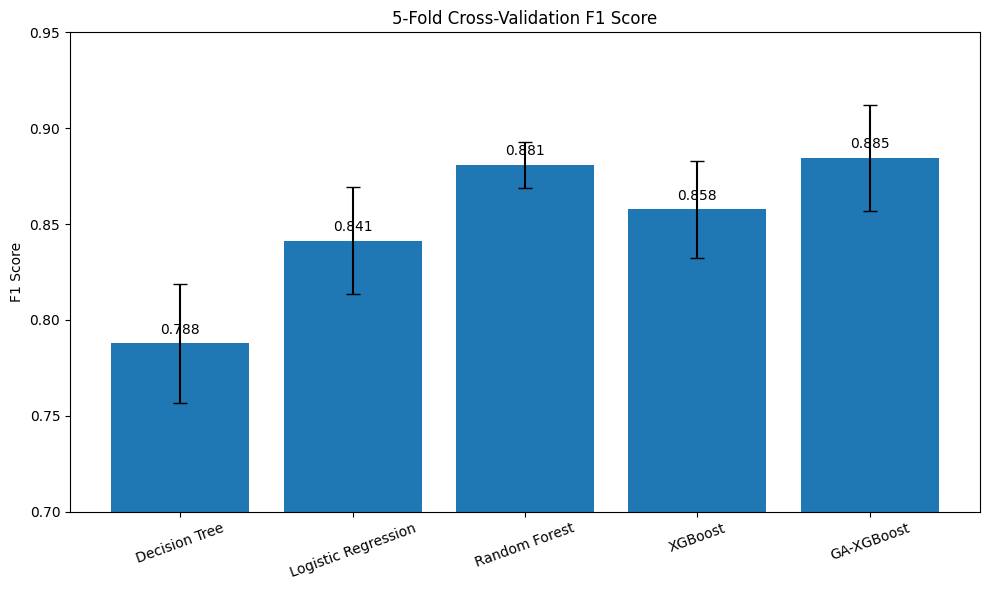

In [ ]:
# F1-score comparison

f1_means = final_cv_table["F1 Mean"]
f1_stds = final_cv_table["F1 Std"]

plt.figure(figsize=(10, 6))

plt.bar(
    models_names,
    f1_means,
    yerr=f1_stds,
    capsize=5
)

plt.ylabel("F1 Score")
plt.title("5-Fold Cross-Validation F1 Score")
plt.ylim(0.7, 0.95)

for i, value in enumerate(f1_means):
    plt.text(
        i,
        value + 0.005,
        f"{value:.3f}",
        ha="center"
    )

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

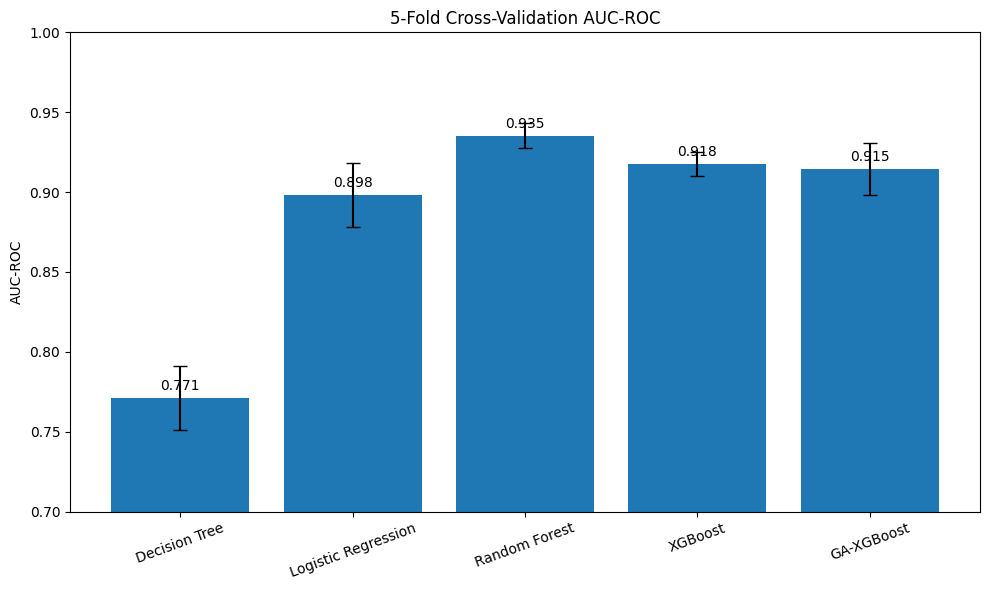

In [ ]:
# AUC-ROC comparison

auc_means = final_cv_table["AUC Mean"]
auc_stds = final_cv_table["AUC Std"]

plt.figure(figsize=(10, 6))

plt.bar(
    models_names,
    auc_means,
    yerr=auc_stds,
    capsize=5
)

plt.ylabel("AUC-ROC")
plt.title("5-Fold Cross-Validation AUC-ROC")
plt.ylim(0.7, 1.0)

for i, value in enumerate(auc_means):
    plt.text(
        i,
        value + 0.005,
        f"{value:.3f}",
        ha="center"
    )

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

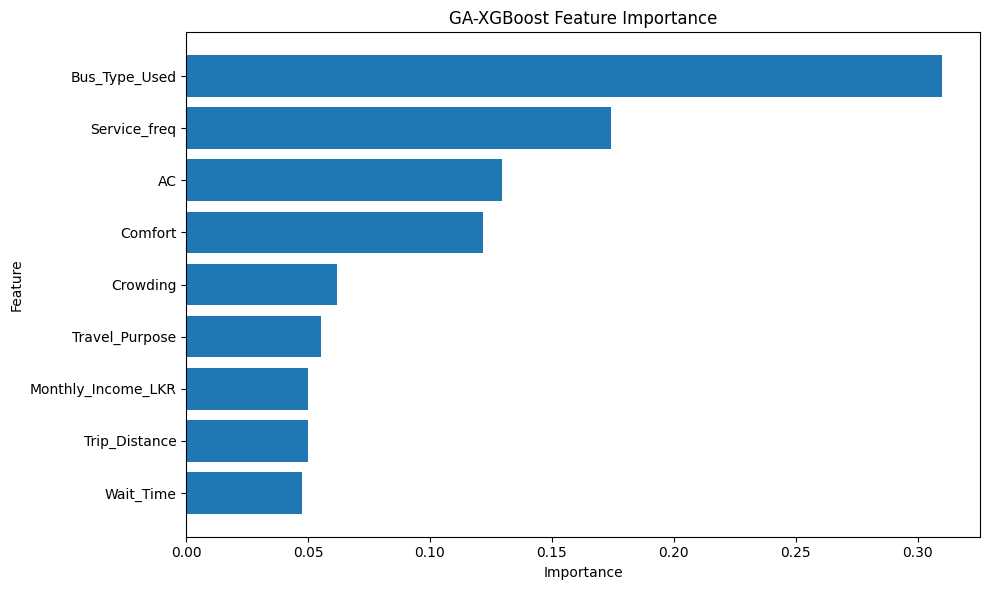

In [ ]:
# Feature Importance of GA-XGBoost

import matplotlib.pyplot as plt

importance = ga_xgb_model.feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": selected_features,
    "Importance": importance
}).sort_values("Importance", ascending=False)

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance_df["Feature"],
    feature_importance_df["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("GA-XGBoost Feature Importance")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
# 5 Random Seeds × 5-Fold Cross-Validation

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import pandas as pd
import numpy as np

seeds = [42, 52, 62, 72, 82]

models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "XGBoost": XGBClassifier(random_state=42, eval_metric='logloss'),
    "GA-XGBoost": XGBClassifier(random_state=42, eval_metric='logloss')
}

all_results = []

for seed in seeds:

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )

    for model_name, model in models.items():

        # Use GA-selected features for GA-XGBoost
        if model_name == "GA-XGBoost":
            X_data = X_train_ga
        else:
            X_data = X_train

        scoring = {
            "accuracy": "accuracy",
            "f1": "f1",
            "auc": "roc_auc"
        }

        scores = cross_validate(
            model,
            X_data,
            y_train,
            cv=cv,
            scoring=scoring
        )

        for i in range(5):
            all_results.append({
                "Seed": seed,
                "Model": model_name,
                "Fold": i + 1,
                "Accuracy": scores["test_accuracy"][i],
                "F1": scores["test_f1"][i],
                "AUC": scores["test_auc"][i]
            })

cv_25_results = pd.DataFrame(all_results)

print("Total CV runs:", len(cv_25_results))
print("Expected:", 5 * 5 * 5)

Total CV runs: 125
Expected: 125


In [ ]:
# Final Mean ± Standard Deviation across 5 seeds × 5 folds

final_25cv_results = (
    cv_25_results
    .groupby("Model")
    .agg(
        Accuracy_Mean=("Accuracy", "mean"),
        Accuracy_Std=("Accuracy", "std"),
        F1_Mean=("F1", "mean"),
        F1_Std=("F1", "std"),
        AUC_Mean=("AUC", "mean"),
        AUC_Std=("AUC", "std")
    )
    .reset_index()
)

# Convert to percentages
for col in [
    "Accuracy_Mean", "Accuracy_Std",
    "F1_Mean", "F1_Std",
    "AUC_Mean", "AUC_Std"
]:
    final_25cv_results[col] = final_25cv_results[col] * 100

print(final_25cv_results.round(2))

                 Model  Accuracy_Mean  Accuracy_Std  F1_Mean  F1_Std  \
0        Decision Tree          77.39          3.98    79.44    3.87   
1           GA-XGBoost          84.43          3.13    86.14    2.84   
2  Logistic Regression          82.14          3.57    84.16    3.21   
3        Random Forest          85.77          2.66    87.36    2.52   
4              XGBoost          83.87          3.30    85.53    3.04   

   AUC_Mean  AUC_Std  
0     77.23     4.00  
1     90.10     2.74  
2     89.28     2.97  
3     92.64     1.92  
4     91.05     2.33  


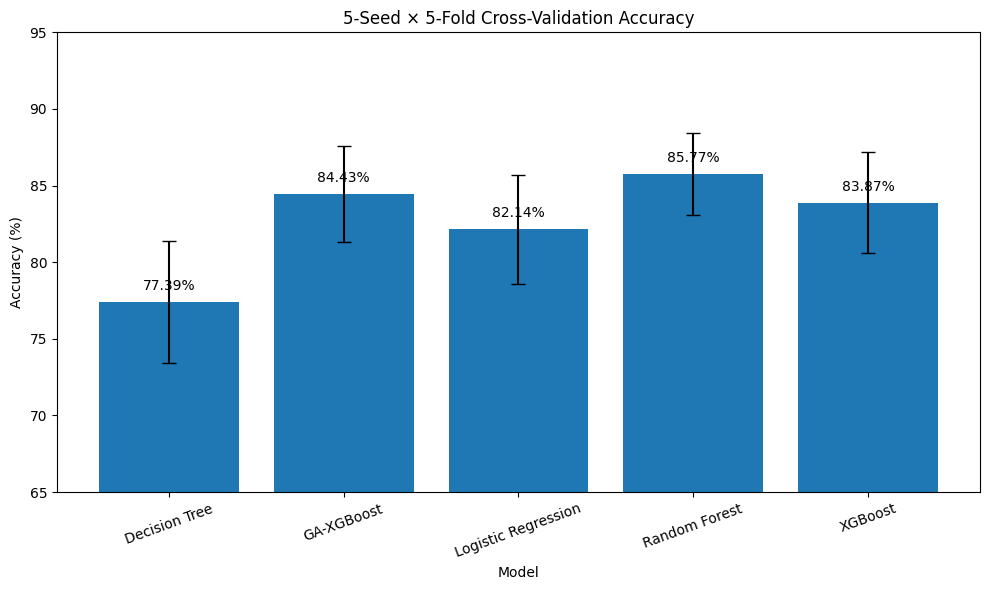

In [ ]:
# Final 25-run Cross-Validation Accuracy

models_names = final_25cv_results["Model"]
accuracy_means = final_25cv_results["Accuracy_Mean"]
accuracy_stds = final_25cv_results["Accuracy_Std"]

plt.figure(figsize=(10, 6))

plt.bar(
    models_names,
    accuracy_means,
    yerr=accuracy_stds,
    capsize=5
)

plt.ylabel("Accuracy (%)")
plt.xlabel("Model")
plt.title("5-Seed × 5-Fold Cross-Validation Accuracy")

plt.ylim(65, 95)

for i, value in enumerate(accuracy_means):
    plt.text(
        i,
        value + 0.8,
        f"{value:.2f}%",
        ha="center"
    )

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

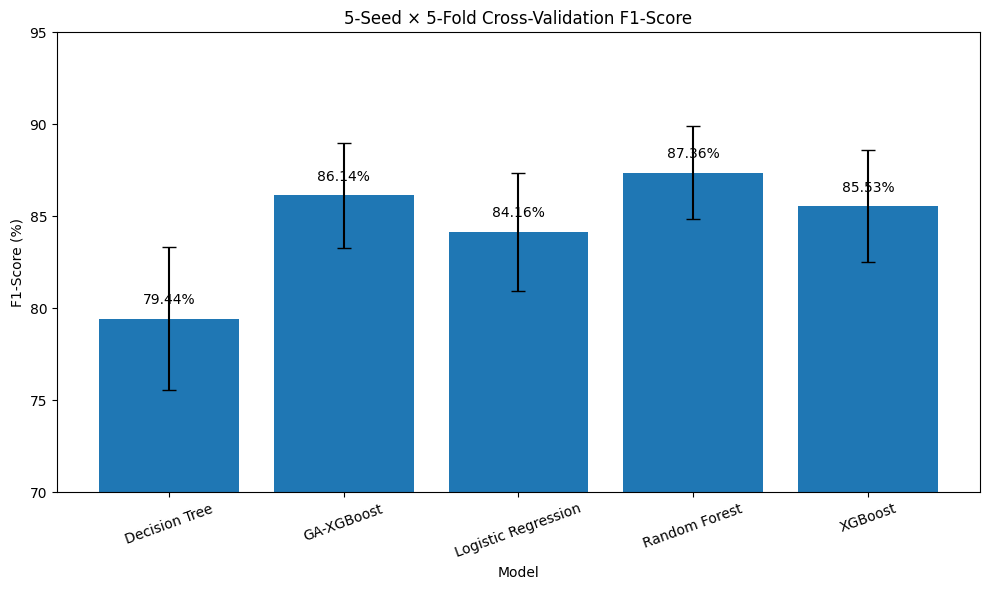

In [ ]:
# Final 25-run Cross-Validation F1-Score

f1_means = final_25cv_results["F1_Mean"]
f1_stds = final_25cv_results["F1_Std"]

plt.figure(figsize=(10, 6))

plt.bar(
    models_names,
    f1_means,
    yerr=f1_stds,
    capsize=5
)

plt.ylabel("F1-Score (%)")
plt.xlabel("Model")
plt.title("5-Seed × 5-Fold Cross-Validation F1-Score")

plt.ylim(70, 95)

for i, value in enumerate(f1_means):
    plt.text(
        i,
        value + 0.8,
        f"{value:.2f}%",
        ha="center"
    )

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

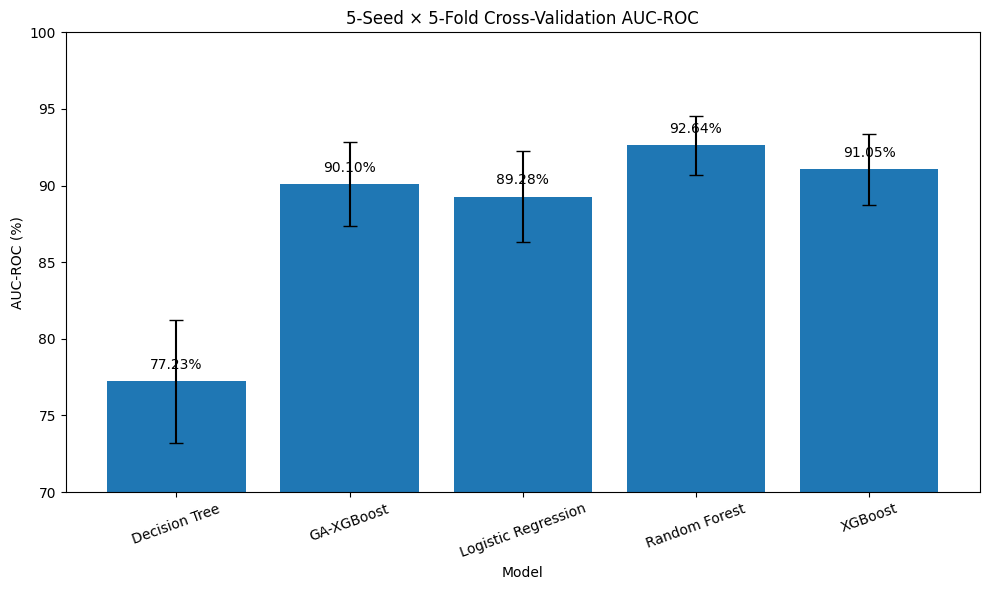

In [ ]:
# Final 25-run Cross-Validation AUC-ROC

auc_means = final_25cv_results["AUC_Mean"]
auc_stds = final_25cv_results["AUC_Std"]

plt.figure(figsize=(10, 6))

plt.bar(
    models_names,
    auc_means,
    yerr=auc_stds,
    capsize=5
)

plt.ylabel("AUC-ROC (%)")
plt.xlabel("Model")
plt.title("5-Seed × 5-Fold Cross-Validation AUC-ROC")

plt.ylim(70, 100)

for i, value in enumerate(auc_means):
    plt.text(
        i,
        value + 0.8,
        f"{value:.2f}%",
        ha="center"
    )

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
# Final 25-run Cross-Validation Results Table

report_table = final_25cv_results.copy()

report_table["Accuracy"] = (
    report_table["Accuracy_Mean"].round(2).astype(str)
    + " ± "
    + report_table["Accuracy_Std"].round(2).astype(str)
    + "%"
)

report_table["F1-Score"] = (
    report_table["F1_Mean"].round(2).astype(str)
    + " ± "
    + report_table["F1_Std"].round(2).astype(str)
    + "%"
)

report_table["AUC-ROC"] = (
    report_table["AUC_Mean"].round(2).astype(str)
    + " ± "
    + report_table["AUC_Std"].round(2).astype(str)
    + "%"
)

report_table = report_table[
    ["Model", "Accuracy", "F1-Score", "AUC-ROC"]
]

print(report_table.to_string(index=False))

              Model      Accuracy      F1-Score       AUC-ROC
      Decision Tree 77.39 ± 3.98% 79.44 ± 3.87%  77.23 ± 4.0%
         GA-XGBoost 84.43 ± 3.13% 86.14 ± 2.84%  90.1 ± 2.74%
Logistic Regression 82.14 ± 3.57% 84.16 ± 3.21% 89.28 ± 2.97%
      Random Forest 85.77 ± 2.66% 87.36 ± 2.52% 92.64 ± 1.92%
            XGBoost  83.87 ± 3.3% 85.53 ± 3.04% 91.05 ± 2.33%


In [ ]:
# Save final cross-validation results

report_table.to_csv(
    "final_25_run_cv_results.csv",
    index=False
)

print("Saved successfully!")

Saved successfully!


In [ ]:
import numpy as np, pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

seeds = [42, 52, 62, 72, 82]

models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "XGBoost": XGBClassifier(random_state=42, eval_metric='logloss'),
}

all_cols = list(X_train.columns)
no_bus = [c for c in all_cols if c != "Bus_Type_Used"]
ga_no_bus = [c for c in selected_features if c != "Bus_Type_Used"]

# (label, model name, model, columns)
experiments = []
for name, m in models.items():
    experiments.append(("With Bus_Type_Used", name, m, all_cols))
    experiments.append(("Without Bus_Type_Used", name, m, no_bus))
experiments.append(("GA features minus Bus_Type_Used (GA not re-run)",
                    "XGBoost", models["XGBoost"], ga_no_bus))

rows = []
for setting, name, model, cols in experiments:
    for seed in seeds:
        cv = StratifiedKFold(5, shuffle=True, random_state=seed)
        s = cross_validate(model, X_train[cols], y_train, cv=cv,
                           scoring={"acc": "accuracy", "f1": "f1", "auc": "roc_auc"})
        for i in range(5):
            rows.append({"Setting": setting, "Model": name,
                         "Accuracy": s["test_acc"][i] * 100,
                         "F1": s["test_f1"][i] * 100,
                         "AUC": s["test_auc"][i] * 100})

abl = pd.DataFrame(rows)
out = abl.groupby(["Setting", "Model"]).agg(
    Acc_Mean=("Accuracy", "mean"), Acc_Std=("Accuracy", "std"),
    F1_Mean=("F1", "mean"), F1_Std=("F1", "std"),
    AUC_Mean=("AUC", "mean"), AUC_Std=("AUC", "std")).round(2)
print(out)
out.to_csv("bus_type_ablation_25run.csv")

                                                                     Acc_Mean  \
Setting                                         Model                           
GA features minus Bus_Type_Used (GA not re-run) XGBoost                 72.45   
With Bus_Type_Used                              Decision Tree           77.39   
                                                Logistic Regression     82.14   
                                                Random Forest           85.77   
                                                XGBoost                 83.87   
Without Bus_Type_Used                           Decision Tree           70.16   
                                                Logistic Regression     75.85   
                                                Random Forest           77.87   
                                                XGBoost                 76.40   

                                                                     Acc_Std  \
Setting                     